# Phân tích tỷ lệ nghỉ việc của nhân viên (HR Employee Attrition Analysis)
Phân tích mô tả các yếu tố liên quan đến việc nhân viên nghỉ việc: phòng ban, làm thêm giờ, thâm niên, độ tuổi, thu nhập, mức độ hài lòng và khoảng cách đi làm.

**Dữ liệu:** `HR_Attrition_Cleaned.csv` (dữ liệu mô phỏng, mỗi dòng là một nhân viên) | **Công cụ:** Python, Pandas, NumPy, Matplotlib, Seaborn

## 1. Thiết lập và tải dữ liệu

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:,.2f}".format)

df = pd.read_csv("HR_Attrition_Cleaned.csv")
df.head()

,Employee_ID,Age,Gender,Department,Years_At_Company,Monthly_Income,Overtime,Job_Satisfaction,Distance_From_Home_km,Attrition,Age_Group,Tenure_Group,Attrition_Flag
0,EMP-2001,39,Female,R&D,4,7950,Yes,3,18,Yes,30-39,3-5 yrs,1
1,EMP-2002,36,Male,Sales,7,5430,No,1,13,No,30-39,6-10 yrs,0
2,EMP-2003,36,Male,IT,7,7910,Yes,1,10,No,30-39,6-10 yrs,0
3,EMP-2004,42,Male,Sales,5,5860,Yes,4,4,No,40-49,3-5 yrs,0
4,EMP-2005,32,Male,Sales,6,5800,No,4,18,No,30-39,6-10 yrs,0


## 2. Kiểm tra dữ liệu

In [2]:
print(f"Số dòng: {df.shape[0]:,} | Số cột: {df.shape[1]}\n")
df.info()

Số dòng: 400 | Số cột: 13

<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 13 columns):
 #   Column                 Non-Null Count  Dtype
---  ------                 --------------  -----
 0   Employee_ID            400 non-null    str  
 1   Age                    400 non-null    int64
 2   Gender                 400 non-null    str  
 3   Department             400 non-null    str  
 4   Years_At_Company       400 non-null    int64
 5   Monthly_Income         400 non-null    int64
 6   Overtime               400 non-null    str  
 7   Job_Satisfaction       400 non-null    int64
 8   Distance_From_Home_km  400 non-null    int64
 9   Attrition              400 non-null    str  
 10  Age_Group              400 non-null    str  
 11  Tenure_Group           400 non-null    str  
 12  Attrition_Flag         400 non-null    int64
dtypes: int64(6), str(7)
memory usage: 40.8 KB


In [3]:
print("Số giá trị thiếu theo từng cột:")
print(df.isna().sum())
print("\nSố dòng trùng lặp:", df.duplicated().sum())
print("Số Employee_ID trùng lặp:", df["Employee_ID"].duplicated().sum())

Số giá trị thiếu theo từng cột:
Employee_ID              0
Age                      0
Gender                   0
Department               0
Years_At_Company         0
Monthly_Income           0
Overtime                 0
Job_Satisfaction         0
Distance_From_Home_km    0
Attrition                0
Age_Group                0
Tenure_Group             0
Attrition_Flag           0
dtype: int64

Số dòng trùng lặp: 0
Số Employee_ID trùng lặp: 0


In [4]:
df.describe()

,Age,Years_At_Company,Monthly_Income,Job_Satisfaction,Distance_From_Home_km,Attrition_Flag
count,400.00,400.00,400.00,400.00,400.00,400.00
mean,36.33,4.99,"6,507.90",2.74,14.63,0.25
std,8.59,3.90,"1,417.72",1.03,8.59,0.43
min,20.00,0.00,"3,690.00",1.00,1.00,0.00
25%,30.00,2.00,"5,420.00",2.00,8.00,0.00
50%,36.00,4.00,"6,395.00",3.00,14.00,0.00
75%,42.00,7.00,"7,590.00",4.00,22.00,0.25
max,60.00,21.00,"11,070.00",4.00,29.00,1.00


## 3. Xác thực dữ liệu và tạo biến mới

In [5]:
required = ["Employee_ID", "Age", "Gender", "Department", "Years_At_Company", "Monthly_Income",
            "Overtime", "Job_Satisfaction", "Distance_From_Home_km", "Attrition",
            "Age_Group", "Tenure_Group", "Attrition_Flag"]
missing_cols = [c for c in required if c not in df.columns]
assert not missing_cols, f"Thiếu các cột bắt buộc: {missing_cols}"

assert df["Employee_ID"].is_unique, "Employee_ID phải là duy nhất"
assert df["Attrition"].isin(["Yes", "No"]).all(), "Attrition chỉ được nhận giá trị Yes hoặc No"
assert df["Overtime"].isin(["Yes", "No"]).all(), "Overtime chỉ được nhận giá trị Yes hoặc No"
assert (df["Attrition_Flag"] == (df["Attrition"] == "Yes").astype(int)).all(), "Attrition_Flag không khớp với Attrition"
assert df["Job_Satisfaction"].isin([1, 2, 3, 4]).all(), "Job_Satisfaction phải nằm trong khoảng 1 đến 4"
assert df["Age"].between(18, 65).all(), "Age nằm ngoài khoảng 18 đến 65"
assert (df["Monthly_Income"] > 0).all() and (df["Years_At_Company"] >= 0).all(), "Thu nhập phải dương và thâm niên không âm"

tenure_order = ["0-2 yrs", "3-5 yrs", "6-10 yrs", "10+ yrs"]
age_order = ["<30", "30-39", "40-49", "50+"]
df["Tenure_Group"] = pd.Categorical(df["Tenure_Group"], categories=tenure_order, ordered=True)
df["Age_Group"] = pd.Categorical(df["Age_Group"], categories=age_order, ordered=True)

df["Income_Band"] = pd.cut(df["Monthly_Income"], bins=[0, 4999, 6999, 8999, np.inf],
                           labels=["Dưới 5.000", "5.000-6.999", "7.000-8.999", "Từ 9.000"])
df["Distance_Band"] = pd.cut(df["Distance_From_Home_km"], bins=[0, 10, 20, np.inf],
                             labels=["1-10 km", "11-20 km", "Trên 20 km"])

print("Tất cả kiểm tra xác thực đều đạt.")

Tất cả kiểm tra xác thực đều đạt.


## 4. Các chỉ số KPI chính

In [6]:
total_employees = len(df)
employees_left = int(df["Attrition_Flag"].sum())
employees_stayed = total_employees - employees_left
attrition_rate = employees_left / total_employees * 100

kpis = pd.DataFrame({
    "Chỉ số": ["Tổng số nhân viên", "Số nhân viên đã nghỉ việc", "Số nhân viên còn làm việc",
               "Tỷ lệ nghỉ việc", "Thu nhập hàng tháng trung bình", "Thâm niên trung bình (năm)"],
    "Giá trị": [f"{total_employees:,}", f"{employees_left:,}", f"{employees_stayed:,}",
                f"{attrition_rate:.1f}%", f"{df['Monthly_Income'].mean():,.2f}",
                f"{df['Years_At_Company'].mean():.1f}"]
})
kpis

,Chỉ số,Giá trị
0,Tổng số nhân viên,400
1,Số nhân viên đã nghỉ việc,100
2,Số nhân viên còn làm việc,300
3,Tỷ lệ nghỉ việc,25.0%
4,Thu nhập hàng tháng trung bình,"6,507.90"
5,Thâm niên trung bình (năm),5.0


## 5. Tỷ lệ nghỉ việc theo từng nhóm

In [7]:
def attrition_by(col):
    out = df.groupby(col, observed=True).agg(**{"Nhân viên": ("Employee_ID", "count"),
                                                "Nghỉ việc": ("Attrition_Flag", "sum")})
    out["Tỷ lệ nghỉ việc (%)"] = out["Nghỉ việc"] / out["Nhân viên"] * 100
    return out

def plot_rate(ax, table, title, order=None):
    data = table.loc[order] if order is not None else table
    sns.barplot(x=data.index.astype(str), y=data["Tỷ lệ nghỉ việc (%)"], color="#4C78A8", ax=ax)
    ax.axhline(attrition_rate, color="#E45756", linestyle="--", linewidth=1.2, label=f"Trung bình chung ({attrition_rate:.1f}%)")
    ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=2)
    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel("Tỷ lệ nghỉ việc (%)")
    ax.set_ylim(0, max(data["Tỷ lệ nghỉ việc (%)"].max(), attrition_rate) * 1.2)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), fontsize=8, frameon=False)

by_department = attrition_by("Department").sort_values("Tỷ lệ nghỉ việc (%)", ascending=False)
by_overtime = attrition_by("Overtime")
by_tenure = attrition_by("Tenure_Group")
by_age = attrition_by("Age_Group")
by_income = attrition_by("Income_Band")
by_satisfaction = attrition_by("Job_Satisfaction")
by_distance = attrition_by("Distance_Band")
by_gender = attrition_by("Gender")

display(by_department)
display(by_overtime)

,Nhân viên,Nghỉ việc,Tỷ lệ nghỉ việc (%)
Department,,,
Sales,121,40,33.06
R&D,119,32,26.89
HR,34,9,26.47
IT,89,14,15.73
Finance,37,5,13.51


,Nhân viên,Nghỉ việc,Tỷ lệ nghỉ việc (%)
Overtime,,,
No,275,54,19.64
Yes,125,46,36.80


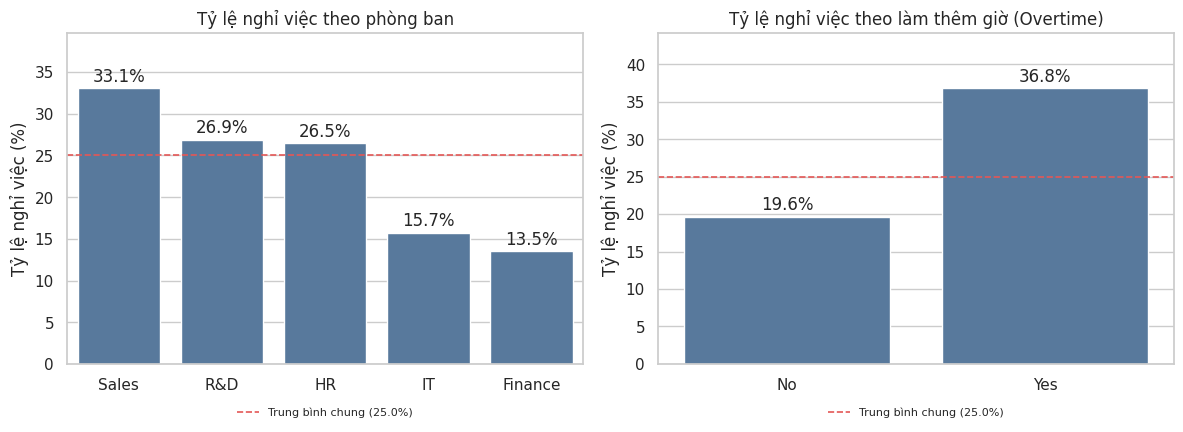

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
plot_rate(axes[0], by_department, "Tỷ lệ nghỉ việc theo phòng ban")
plot_rate(axes[1], by_overtime, "Tỷ lệ nghỉ việc theo làm thêm giờ (Overtime)")
plt.tight_layout()
plt.show()

In [9]:
display(by_tenure)
display(by_age)

,Nhân viên,Nghỉ việc,Tỷ lệ nghỉ việc (%)
Tenure_Group,,,
0-2 yrs,139,45,32.37
3-5 yrs,116,29,25.00
6-10 yrs,100,18,18.00
10+ yrs,45,8,17.78


,Nhân viên,Nghỉ việc,Tỷ lệ nghỉ việc (%)
Age_Group,,,
<30,88,29,32.95
30-39,169,38,22.49
40-49,113,28,24.78
50+,30,5,16.67


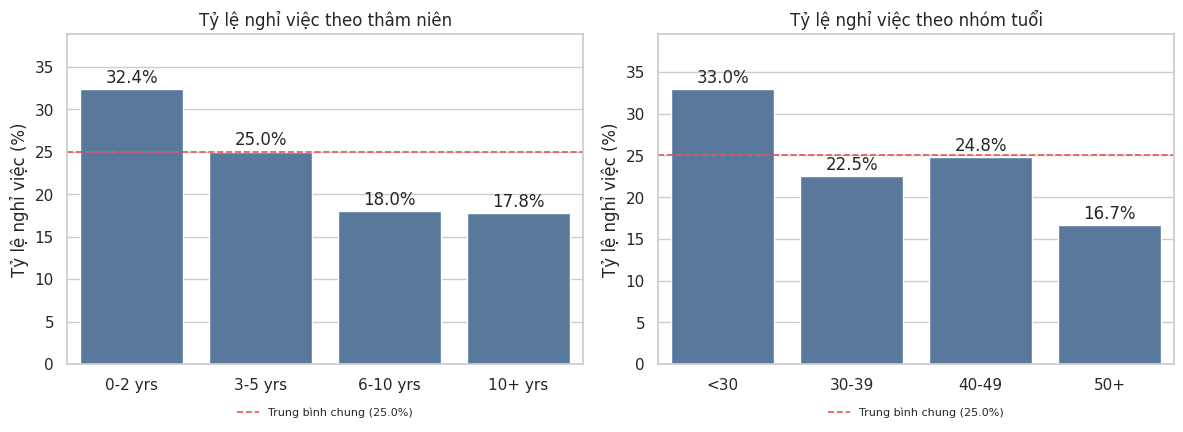

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
plot_rate(axes[0], by_tenure, "Tỷ lệ nghỉ việc theo thâm niên")
plot_rate(axes[1], by_age, "Tỷ lệ nghỉ việc theo nhóm tuổi")
plt.tight_layout()
plt.show()

In [11]:
display(by_income)
display(by_satisfaction)
display(by_distance)
display(by_gender)

,Nhân viên,Nghỉ việc,Tỷ lệ nghỉ việc (%)
Income_Band,,,
Dưới 5.000,61,24,39.34
5.000-6.999,187,49,26.20
7.000-8.999,136,26,19.12
Từ 9.000,16,1,6.25


,Nhân viên,Nghỉ việc,Tỷ lệ nghỉ việc (%)
Job_Satisfaction,,,
1,66,28,42.42
2,81,22,27.16
3,145,30,20.69
4,108,20,18.52


,Nhân viên,Nghỉ việc,Tỷ lệ nghỉ việc (%)
Distance_Band,,,
1-10 km,152,37,24.34
11-20 km,121,31,25.62
Trên 20 km,127,32,25.20


,Nhân viên,Nghỉ việc,Tỷ lệ nghỉ việc (%)
Gender,,,
Female,191,40,20.94
Male,209,60,28.71


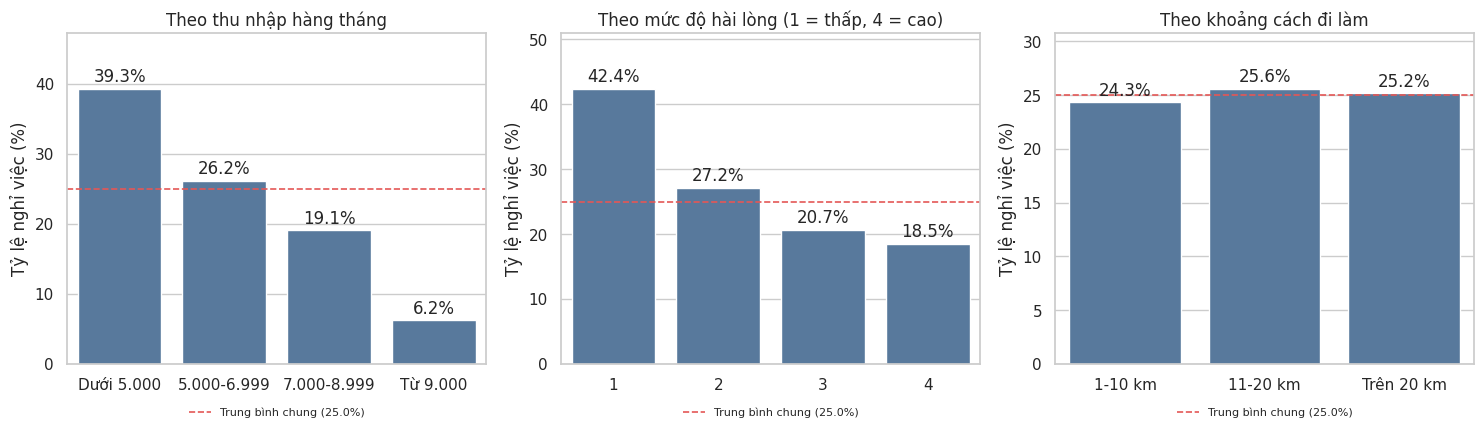

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
plot_rate(axes[0], by_income, "Theo thu nhập hàng tháng")
plot_rate(axes[1], by_satisfaction, "Theo mức độ hài lòng (1 = thấp, 4 = cao)")
plot_rate(axes[2], by_distance, "Theo khoảng cách đi làm")
plt.tight_layout()
plt.show()

## 6. So sánh nhân viên đã nghỉ việc và còn làm việc

In [13]:
compare = df.groupby("Attrition").agg(**{
    "Số nhân viên": ("Employee_ID", "count"),
    "Tuổi trung bình": ("Age", "mean"),
    "Thâm niên trung bình (năm)": ("Years_At_Company", "mean"),
    "Thu nhập trung vị": ("Monthly_Income", "median"),
    "Khoảng cách trung bình (km)": ("Distance_From_Home_km", "mean"),
    "Mức hài lòng trung bình": ("Job_Satisfaction", "mean"),
})
compare.index = compare.index.map({"Yes": "Đã nghỉ việc", "No": "Còn làm việc"})
compare

,Số nhân viên,Tuổi trung bình,Thâm niên trung bình (năm),Thu nhập trung vị,Khoảng cách trung bình (km),Mức hài lòng trung bình
Attrition,,,,,,
Còn làm việc,300,36.73,5.27,"6,615.00",14.65,2.84
Đã nghỉ việc,100,35.12,4.14,"5,580.00",14.58,2.42


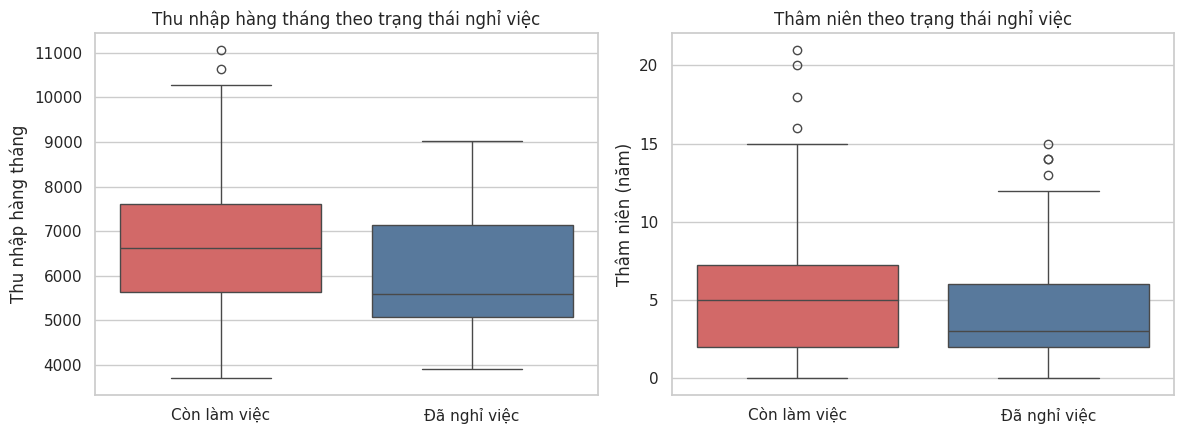

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.boxplot(data=df, x="Attrition", y="Monthly_Income", order=["No", "Yes"], palette=["#4C78A8", "#E45756"], hue="Attrition", legend=False, ax=axes[0])
axes[0].set_title("Thu nhập hàng tháng theo trạng thái nghỉ việc")
axes[0].set_xticks([0, 1], ["Còn làm việc", "Đã nghỉ việc"])
axes[0].set_xlabel("")
axes[0].set_ylabel("Thu nhập hàng tháng")
sns.boxplot(data=df, x="Attrition", y="Years_At_Company", order=["No", "Yes"], palette=["#4C78A8", "#E45756"], hue="Attrition", legend=False, ax=axes[1])
axes[1].set_title("Thâm niên theo trạng thái nghỉ việc")
axes[1].set_xticks([0, 1], ["Còn làm việc", "Đã nghỉ việc"])
axes[1].set_xlabel("")
axes[1].set_ylabel("Thâm niên (năm)")
plt.tight_layout()
plt.show()

## 7. Kết luận rút ra từ dữ liệu

In [15]:
MIN_GROUP = 30
rate = "Tỷ lệ nghỉ việc (%)"

dept_valid = by_department[by_department["Nhân viên"] >= MIN_GROUP]
ot_yes, ot_no = by_overtime.loc["Yes", rate], by_overtime.loc["No", rate]
low_sat = df[df["Job_Satisfaction"] <= 2]["Attrition_Flag"].mean() * 100
high_sat = df[df["Job_Satisfaction"] >= 3]["Attrition_Flag"].mean() * 100
inc_left = df[df["Attrition"] == "Yes"]["Monthly_Income"].median()
inc_stay = df[df["Attrition"] == "No"]["Monthly_Income"].median()

print(f"1. Tỷ lệ nghỉ việc chung là {attrition_rate:.1f}% ({employees_left} trên {total_employees} nhân viên).")
print(f"2. Nhân viên làm thêm giờ nghỉ việc {ot_yes:.1f}%, so với {ot_no:.1f}% ở nhóm không làm thêm giờ (gấp {ot_yes / ot_no:.1f} lần).")
print(f"3. Trong các phòng ban có từ {MIN_GROUP} nhân viên trở lên, {dept_valid[rate].idxmax()} có tỷ lệ nghỉ việc cao nhất "
      f"({dept_valid[rate].max():.1f}%) và {dept_valid[rate].idxmin()} thấp nhất ({dept_valid[rate].min():.1f}%).")
print(f"4. Nhóm thâm niên 0-2 năm nghỉ việc {by_tenure.loc['0-2 yrs', rate]:.1f}%, trong khi nhóm trên 10 năm là {by_tenure.loc['10+ yrs', rate]:.1f}%.")
print(f"5. Nhân viên có mức hài lòng 1-2 nghỉ việc {low_sat:.1f}%, so với {high_sat:.1f}% ở mức hài lòng 3-4.")
print(f"6. Thu nhập trung vị của nhóm đã nghỉ việc là {inc_left:,.0f}, so với {inc_stay:,.0f} của nhóm còn làm việc.")

1. Tỷ lệ nghỉ việc chung là 25.0% (100 trên 400 nhân viên).
2. Nhân viên làm thêm giờ nghỉ việc 36.8%, so với 19.6% ở nhóm không làm thêm giờ (gấp 1.9 lần).
3. Trong các phòng ban có từ 30 nhân viên trở lên, Sales có tỷ lệ nghỉ việc cao nhất (33.1%) và Finance thấp nhất (13.5%).
4. Nhóm thâm niên 0-2 năm nghỉ việc 32.4%, trong khi nhóm trên 10 năm là 17.8%.
5. Nhân viên có mức hài lòng 1-2 nghỉ việc 34.0%, so với 19.8% ở mức hài lòng 3-4.
6. Thu nhập trung vị của nhóm đã nghỉ việc là 5,580, so với 6,615 của nhóm còn làm việc.


## 8. Hạn chế
- Dữ liệu là dữ liệu mô phỏng; các kết quả minh họa quy trình phân tích và không phản ánh doanh nghiệp thực tế.
- Đây là phân tích mô tả. Mối liên hệ giữa các yếu tố và việc nghỉ việc không chứng minh quan hệ nhân quả.
- Dữ liệu chỉ có một thời điểm, không có ngày nghỉ việc nên không thể phân tích xu hướng theo thời gian.
- Một số nhóm có số nhân viên nhỏ (ví dụ phòng ban HR), nên tỷ lệ của các nhóm này có thể biến động mạnh.
- Dữ liệu không có thông tin về lý do nghỉ việc, chính sách lương thưởng hay điều kiện thị trường.